In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Descripción general del dataset

df = pd.read_csv("datos_furbo.csv")

print(df.head())


            date   clock                  stadium class attendance  Home Team  \
0  28th May 2023  4:30pm         Emirates Stadium     h     60,095          2   
1  28th May 2023  4:30pm               Villa Park     h     42,212          7   
2  28th May 2023  4:30pm  Gtech Community Stadium     h     17,120          9   
3  28th May 2023  4:30pm          Stamford Bridge     d     40,130         12   
4  28th May 2023  4:30pm            Selhurst Park     d     25,198         11   

   Goals Home  Away Team  Away Goals  home_possessions  ...  away_duels  \
0           5         13           0              51.0  ...        52.2   
1           2          6           1              40.3  ...        47.8   
2           1          1           0              34.4  ...        50.0   
3           1          4           1              64.4  ...        45.5   
4           1         16           1              66.0  ...        41.7   

   home_saves  away_saves  home_fouls  away_fouls  home_yellow

Estadísticas de asistencia:
count     1140.000000
mean     26584.311404
std      22827.967261
min          0.000000
25%          0.000000
50%      29288.500000
75%      41889.250000
max      75546.000000
Name: attendance, dtype: float64


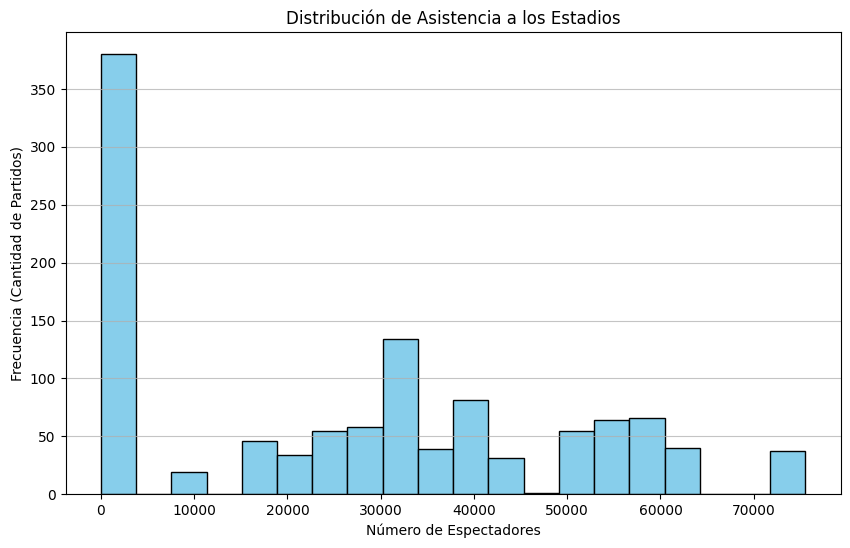

In [2]:

# Distribución de asistencia a los estadios

df['attendance'] = df['attendance'].str.replace(',', '').astype(int)

print("Estadísticas de asistencia:")
print(df['attendance'].describe())


plt.figure(figsize=(10, 6))
plt.hist(df['attendance'], bins=20, color='skyblue', edgecolor='black')
plt.title("Distribución de Asistencia a los Estadios")
plt.xlabel("Número de Espectadores")
plt.ylabel("Frecuencia (Cantidad de Partidos)")
plt.grid(axis='y', alpha=0.75)
plt.show()

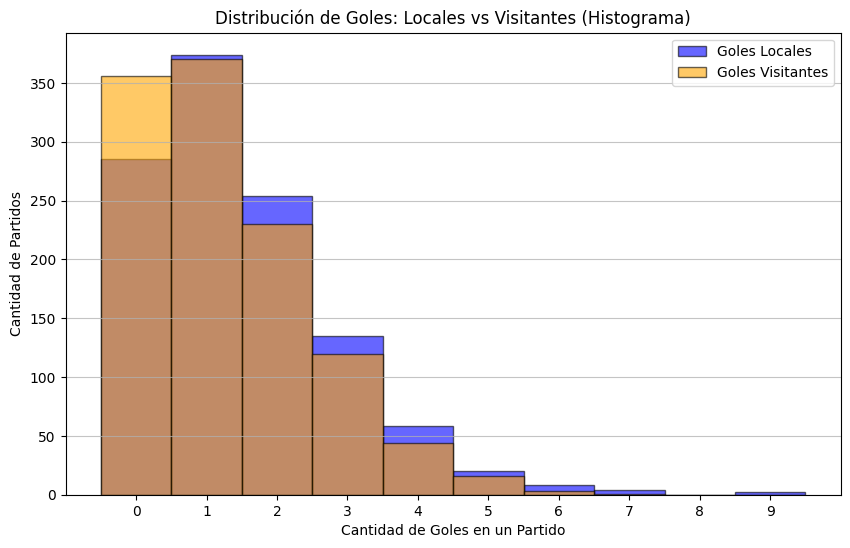

In [3]:
#Análisis de resultados

# Distribución de goles locales vs visitantes.

plt.figure(figsize=(10, 6))
plt.hist(df['Goals Home'], bins=range(0, 11), alpha=0.6, label='Goles Locales', color='blue', align='left', edgecolor='black')
plt.hist(df['Away Goals'], bins=range(0, 11), alpha=0.6, label='Goles Visitantes', color='orange', align='left', edgecolor='black')
plt.title('Distribución de Goles: Locales vs Visitantes (Histograma)')
plt.xlabel('Cantidad de Goles en un Partido')
plt.ylabel('Cantidad de Partidos')
plt.xticks(range(0, 10))
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

<Figure size 1200x600 with 0 Axes>

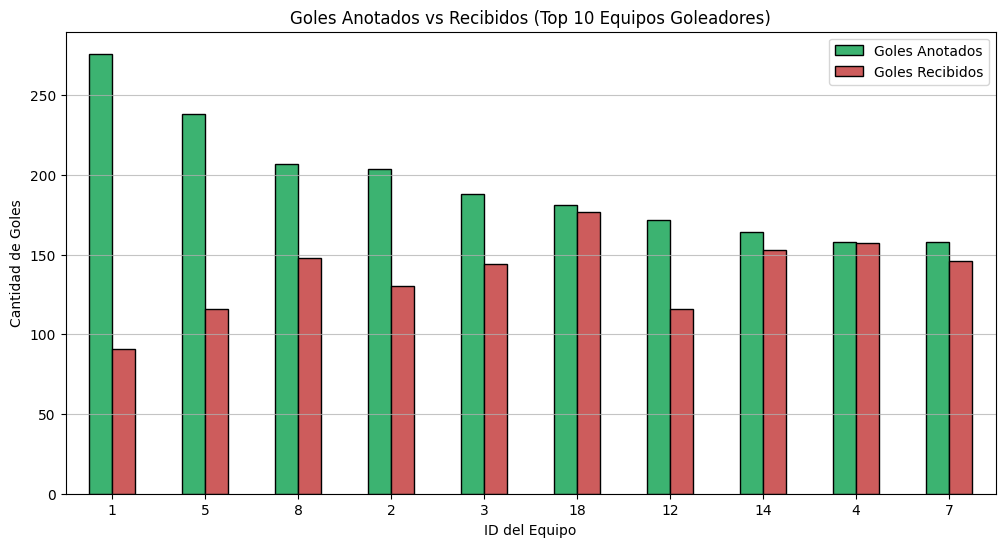

In [22]:
# Equipos con mayor número de goles anotados y recibidos.

goles_anotados_casa = df.groupby('Home Team')['Goals Home'].sum()
goles_anotados_fuera = df.groupby('Away Team')['Away Goals'].sum()
total_anotados = goles_anotados_casa.add(goles_anotados_fuera, fill_value=0)

goles_recibidos_casa = df.groupby('Home Team')['Away Goals'].sum()
goles_recibidos_fuera = df.groupby('Away Team')['Goals Home'].sum()
total_recibidos = goles_recibidos_casa.add(goles_recibidos_fuera, fill_value=0)

df_goles = pd.DataFrame({
    'Anotados': total_anotados,
    'Recibidos': total_recibidos
})

df_goles_top = df_goles.sort_values(by='Anotados', ascending=False).head(10)

df_goles_top.index = df_goles_top.index.astype(int).astype(str)

plt.figure(figsize=(12, 6))
df_goles_top.plot(kind='bar', figsize=(12, 6), color=['mediumseagreen', 'indianred'], edgecolor='black')
plt.title('Goles Anotados vs Recibidos (Top 10 Equipos Goleadores)')
plt.xlabel('ID del Equipo')
plt.ylabel('Cantidad de Goles')
plt.xticks(rotation=0)
plt.legend(['Goles Anotados', 'Goles Recibidos'])
plt.grid(axis='y', alpha=0.75)
plt.show()

<Figure size 800x500 with 0 Axes>

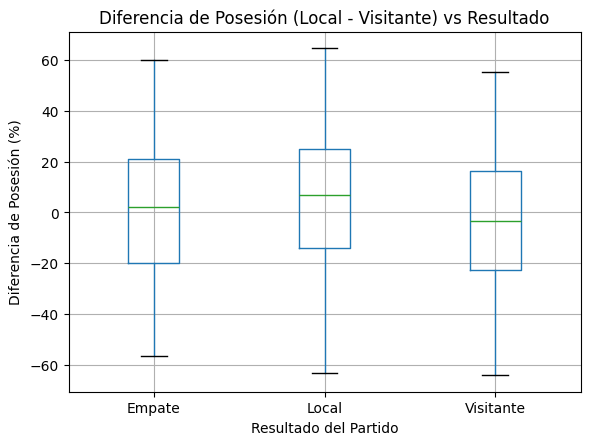

In [14]:

# Relación entre posesión y resultado del partido

condiciones = [df['Goals Home'] > df['Away Goals'], df['Goals Home'] < df['Away Goals']]
df['Resultado'] = np.select(condiciones, ['Local', 'Visitante'], default='Empate')

df['diff_possessions'] = df['home_possessions'] - df['away_possessions']

plt.figure(figsize=(8, 5))
df.boxplot(column='diff_possessions', by='Resultado', grid=True)
plt.title('Diferencia de Posesión (Local - Visitante) vs Resultado')
plt.suptitle('')
plt.xlabel('Resultado del Partido')
plt.ylabel('Diferencia de Posesión (%)')
plt.show()

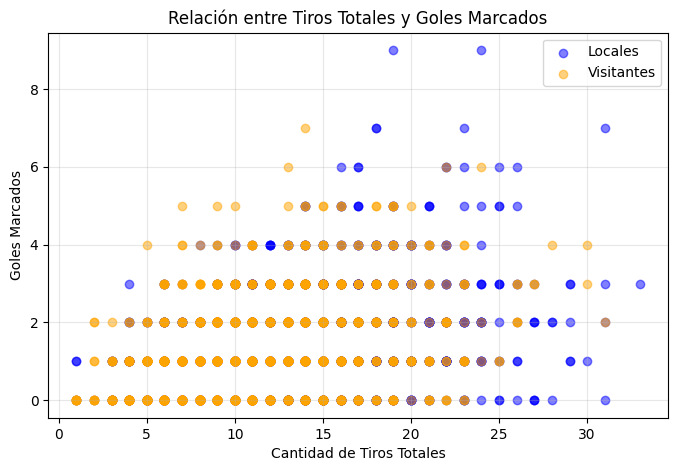

In [6]:
# Relación entre tiros y goles.

plt.figure(figsize=(8, 5))

plt.scatter(df['home_shots'], df['Goals Home'], color='blue', alpha=0.5, label='Locales')

plt.scatter(df['away_shots'], df['Away Goals'], color='orange', alpha=0.5, label='Visitantes')

plt.title('Relación entre Tiros Totales y Goles Marcados')
plt.xlabel('Cantidad de Tiros Totales')
plt.ylabel('Goles Marcados')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

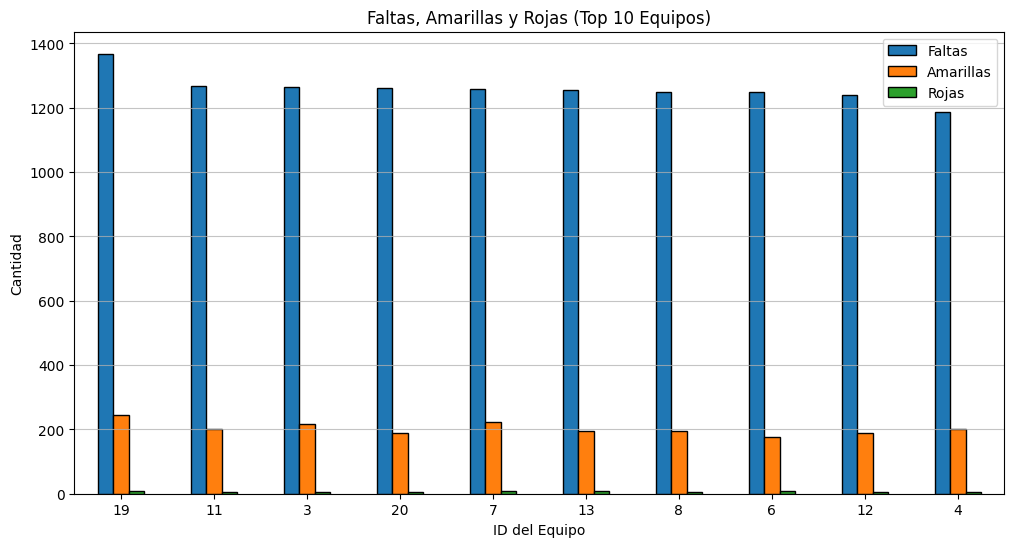

In [15]:
# Análisis de faltas y tarjetas

faltas_totales = df.groupby('Home Team')['home_fouls'].sum().add(df.groupby('Away Team')['away_fouls'].sum(), fill_value=0)
amarillas_totales = df.groupby('Home Team')['home_yellow'].sum().add(df.groupby('Away Team')['away_yellow'].sum(), fill_value=0)
rojas_totales = df.groupby('Home Team')['home_red'].sum().add(df.groupby('Away Team')['away_red'].sum(), fill_value=0)

df_sanciones = pd.DataFrame({
    'Faltas': faltas_totales,
    'Amarillas': amarillas_totales,
    'Rojas': rojas_totales
})

df_sanciones = df_sanciones.sort_values(by='Faltas', ascending=False)

df_sanciones.head(10).plot(kind='bar', figsize=(12, 6), edgecolor='black')
plt.title('Faltas, Amarillas y Rojas (Top 10 Equipos)')
plt.xlabel('ID del Equipo')
plt.ylabel('Cantidad')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.75)
plt.show()

<Figure size 800x500 with 0 Axes>

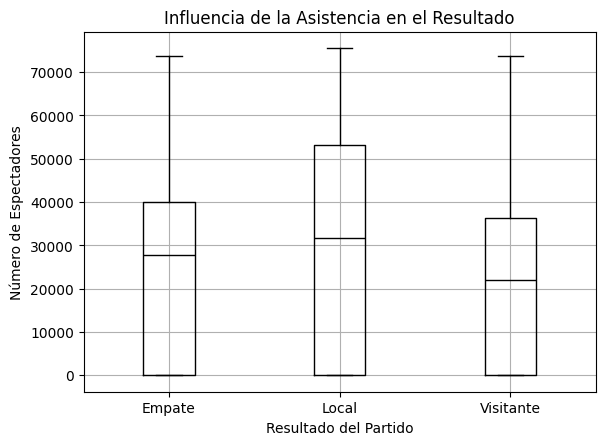

In [17]:
# Relación entre asistencia y resultado

if df['attendance'].dtype == 'O':
    df['attendance'] = df['attendance'].str.replace(',', '').astype(float)

plt.figure(figsize=(8, 5))
df.boxplot(column='attendance', by='Resultado', grid=True, color='black')
plt.title('Influencia de la Asistencia en el Resultado')
plt.suptitle('')
plt.xlabel('Resultado del Partido')
plt.ylabel('Número de Espectadores')
plt.show()

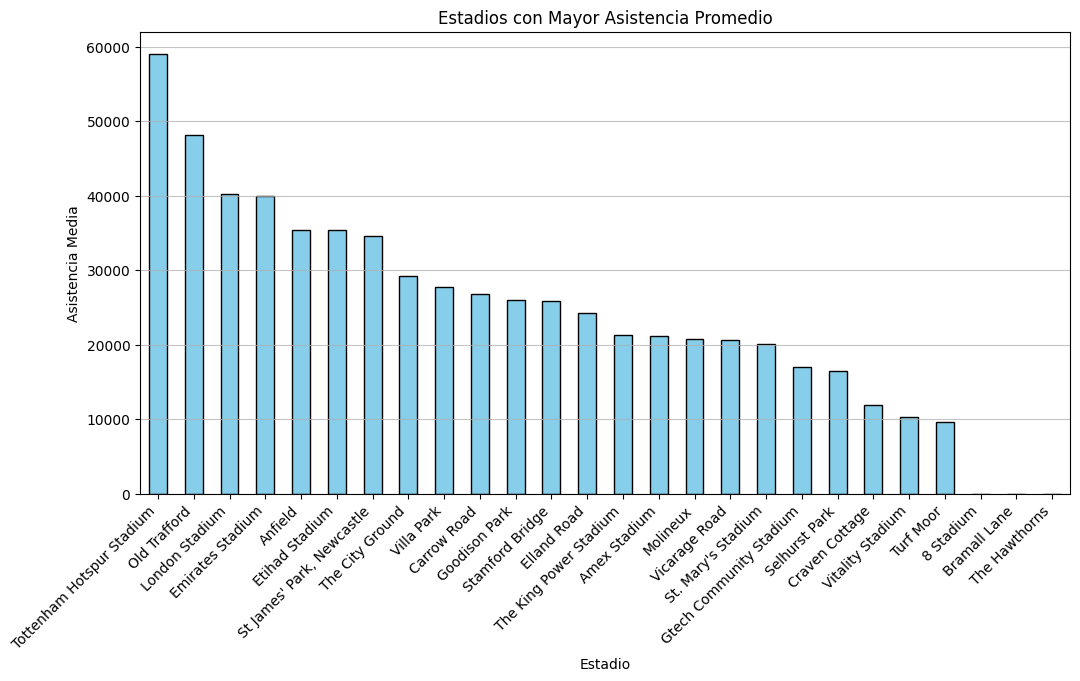

In [18]:
# Estadios con mayor asistencia promedio

asistencia_promedio = df.groupby('stadium')['attendance'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
asistencia_promedio.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Estadios con Mayor Asistencia Promedio')
plt.xlabel('Estadio')
plt.ylabel('Asistencia Media')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.75)
plt.show()

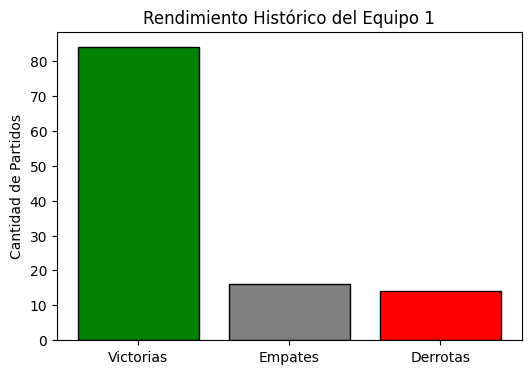

In [10]:

# Gráficos de barras para equipos con más victorias, derrotas, empates.


df['Gana_Local'] = df['Goals Home'] > df['Away Goals']
df['Gana_Visit'] = df['Goals Home'] < df['Away Goals']
df['Es_Empate'] = df['Goals Home'] == df['Away Goals']


equipo_id = 1
victorias = df[df['Home Team'] == equipo_id]['Gana_Local'].sum() + df[df['Away Team'] == equipo_id]['Gana_Visit'].sum()
empates = df[(df['Home Team'] == equipo_id) | (df['Away Team'] == equipo_id)]['Es_Empate'].sum()
derrotas = df[df['Home Team'] == equipo_id]['Gana_Visit'].sum() + df[df['Away Team'] == equipo_id]['Gana_Local'].sum()

plt.figure(figsize=(6, 4))
plt.bar(['Victorias', 'Empates', 'Derrotas'], [victorias, empates, derrotas], color=['green', 'gray', 'red'], edgecolor='black')
plt.title(f'Rendimiento Histórico del Equipo {equipo_id}')
plt.ylabel('Cantidad de Partidos')
plt.show()

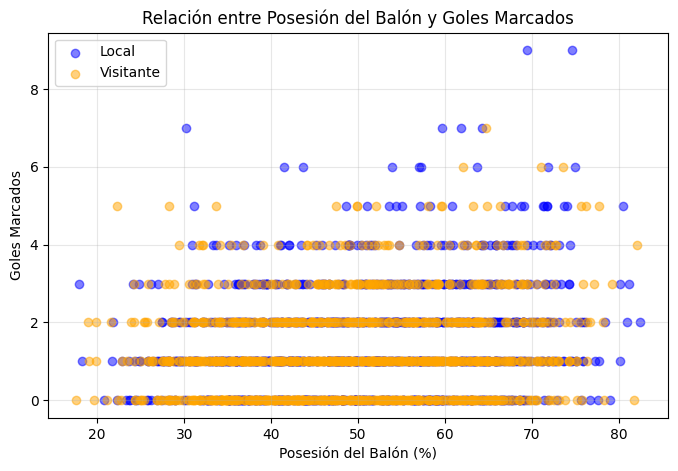

In [11]:
# Diagramas de dispersión entre posesión y goles.

plt.figure(figsize=(8, 5))
plt.scatter(df['home_possessions'], df['Goals Home'], color='blue', alpha=0.5, label='Local')
plt.scatter(df['away_possessions'], df['Away Goals'], color='orange', alpha=0.5, label='Visitante')
plt.title('Relación entre Posesión del Balón y Goles Marcados')
plt.xlabel('Posesión del Balón (%)')
plt.ylabel('Goles Marcados')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

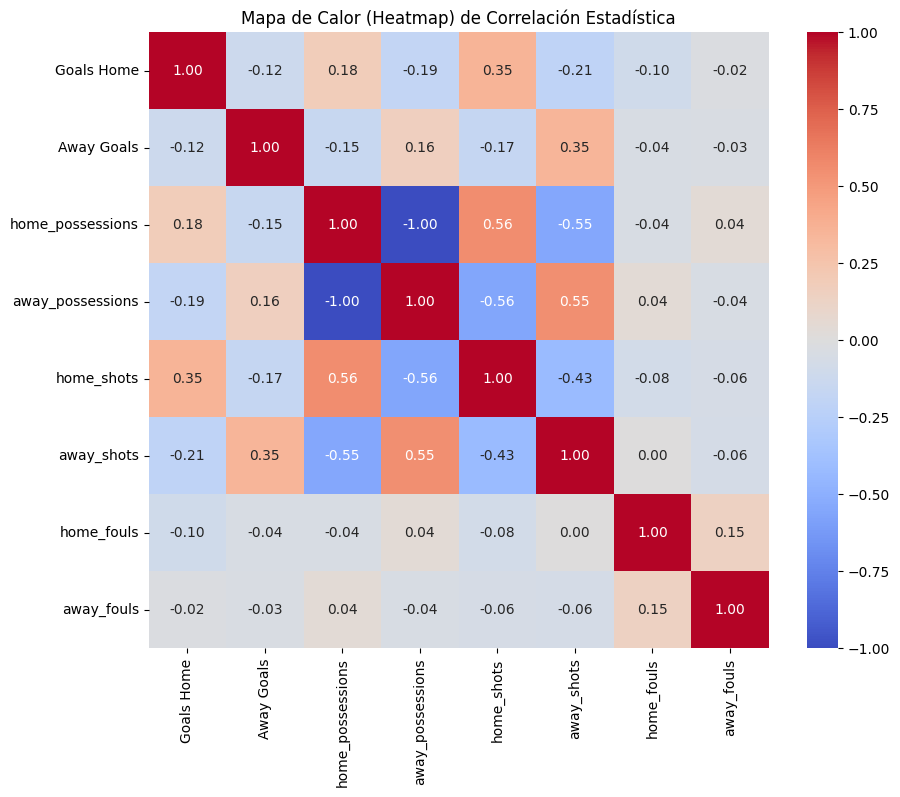

In [12]:
# Heatmaps de correlación entre variables estadísticas.

columnas_stats = ['Goals Home', 'Away Goals', 'home_possessions', 'away_possessions',
                  'home_shots', 'away_shots', 'home_fouls', 'away_fouls']

matriz_correlacion = df[columnas_stats].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Mapa de Calor (Heatmap) de Correlación Estadística")
plt.show()

# **Conclusiones**


Hay una diferencia enorme de nivel. Los Equipos 1 y 5 dominan totalmente marcando goles, mientras que el 19 y el 20 son los que peor defienden, recibiendo más de 200 goles en contra.

<br>

La posesión no está tan relacionada con la victoria. Se puede ganar con poca posesión, y el gráfico de dispersión muestra que tirar mucho no sirve si no hay puntería.

<br>

Los estadios grandes como el del Tottenham o Old Trafford tienen muchísima asistencia, y los datos confirman que los que juegan en local ganan la mayoría de las veces.

<br>

El Equipo 19 es el que más faltas y tarjetas amarillas ha tenido de los equipos. En cambio, el Equipo 17 es el que más ha tenido tarjetas rojas.